# EO4FLOOD flood extent: one scene and a sensor comparison

EO4FLOOD flood-extent products map water or inundation from Sentinel-1, Sentinel-2 and VIIRS.
This Niger example first displays a Sentinel-2 water classification, then compares it with
Sentinel-1 flood detections from 15 September 2020. Each raster is read directly from the online
GeoTIFF asset in its STAC item.

## Categorical maps and spatial extent

The products are GeoTIFF rasters, with sensor, nominal pixel size, basin and dates encoded in the
filename. Sentinel-1 and Sentinel-2 carry one acquisition date; VIIRS carries the start and end of
its composite. The final date identifies product generation.

The example rasters are in WGS 84 (EPSG:4326), so their axes are longitude and latitude. Sentinel-1
and VIIRS are distributed on a grid of about 30 m, while Sentinel-2 uses about 10 m. The VIIRS output
grid spacing does not imply that its native observation resolution equals Sentinel-1's.

Large rasters are read as display-sized first-band previews with nearest-neighbour resampling,
which preserves the categorical codes. The displayed samples are not suitable for computing
full-resolution pixel counts or flooded area. The geographic extent remains that of each source raster.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import rasterio
from rasterio.enums import Resampling
from rasterio.plot import plotting_extent
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


PREVIEW_SIZE = 1200

In [2]:
def read_preview(path):
    """Read only a display-sized first band; preserve categorical pixel values."""
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"), rasterio.open(path) as source:
        scale = min(1, PREVIEW_SIZE / max(source.height, source.width))
        data = source.read(1, out_shape=(max(1, round(source.height * scale)),
                                         max(1, round(source.width * scale))),
                           resampling=Resampling.nearest)
        extent = plotting_extent(source)
        crs = source.crs
    return data, extent, crs


def plot_classes(data, extent, crs, colors, labels, ax, title):
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(len(colors) + 1) - 0.5, cmap.N)
    ax.imshow(data, extent=extent, cmap=cmap, norm=norm, interpolation="nearest")
    ax.legend(handles=[Patch(facecolor=color, edgecolor="gray", label=label)
                       for color, label in zip(colors, labels)], loc="upper right")
    ax.set(title=title, xlabel=f"X ({crs})", ylabel=f"Y ({crs})")

## Sentinel-2 water classification

The Sentinel-2 product uses `0` for NoData, `1` for other land cover, `2` for water, and `3` for cloud.
Other land cover includes vegetation, bare soil and urban areas. Water and cloud receive separate colours;
NoData is transparent.

Sentinel-2 shows water, not flooding alone. Its water class includes permanent rivers and lakes.
A change relative to a water map outside an event is needed to attribute newly inundated areas.
Optical observations can be obscured by cloud.

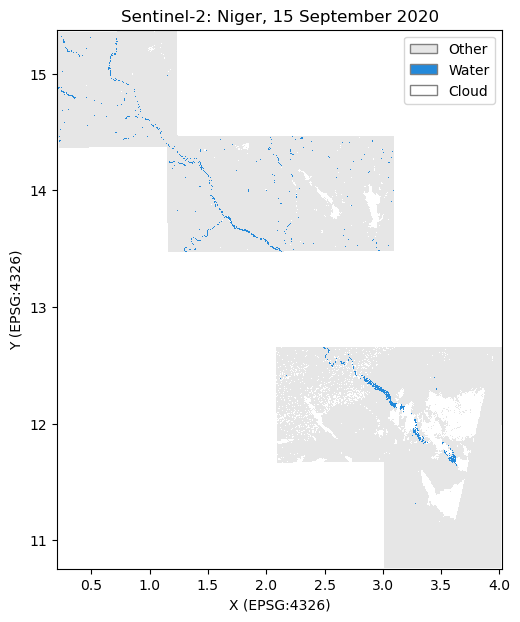

In [3]:
s2_path = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/Flood_extent/Niger/Flood_extent/From_S2/EO4FLOOD_S2_Flood_Extent_10m_nigr_20200915_20250701.tif'
s2, s2_extent, s2_crs = read_preview(s2_path)
s2 = np.ma.masked_equal(s2, 0) - 1
fig, ax = plt.subplots(figsize=(9, 7))
plot_classes(s2, s2_extent, s2_crs, ["#e6e6e6", "#2389da", "white"], ["Other", "Water", "Cloud"], ax, "Sentinel-2: Niger, 15 September 2020")
plt.show()

## Sentinel-1 flood classification

The Sentinel-1 flood extent product uses the following pixel values:

- `0`: non-flooded;
- `1`: flooded, detected in a single polarization band (VV or VH);
- `2`: flooded, detected in both polarization bands;
- `255`: NoData.

Values 1 and 2 are both considered flooded pixels. Separate shades distinguish detections based
on a single polarization from detections supported by both. Sentinel-1 radar can observe through
cloud and at night.

In [4]:
s1_path = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/eo4flood/Flood_extent/Niger/Flood_extent/From_S1/Niger_20200915/EO4FLOOD_S1_FloodedExtent_30m_nigr_20200915_20250728.tif'
s1, s1_extent, s1_crs = read_preview(s1_path)
s1 = np.ma.masked_equal(s1, 255)

## Two views of the same event

The two rasters are displayed independently, preserving each source's own geographic bounds.
They can differ in footprint, resolution and observed conditions. Sentinel-1 distinguishes flood
detections by polarization support; Sentinel-2 distinguishes water, other land cover and cloud.
Water pixels should not be interpreted directly as newly flooded areas.

The sensors do not see the same flood in the same way: radar works through cloud and at night,
optical water classification depends on visible conditions, and VIIRS provides multi-day composites.
Comparison provides context that a single sensor cannot supply.

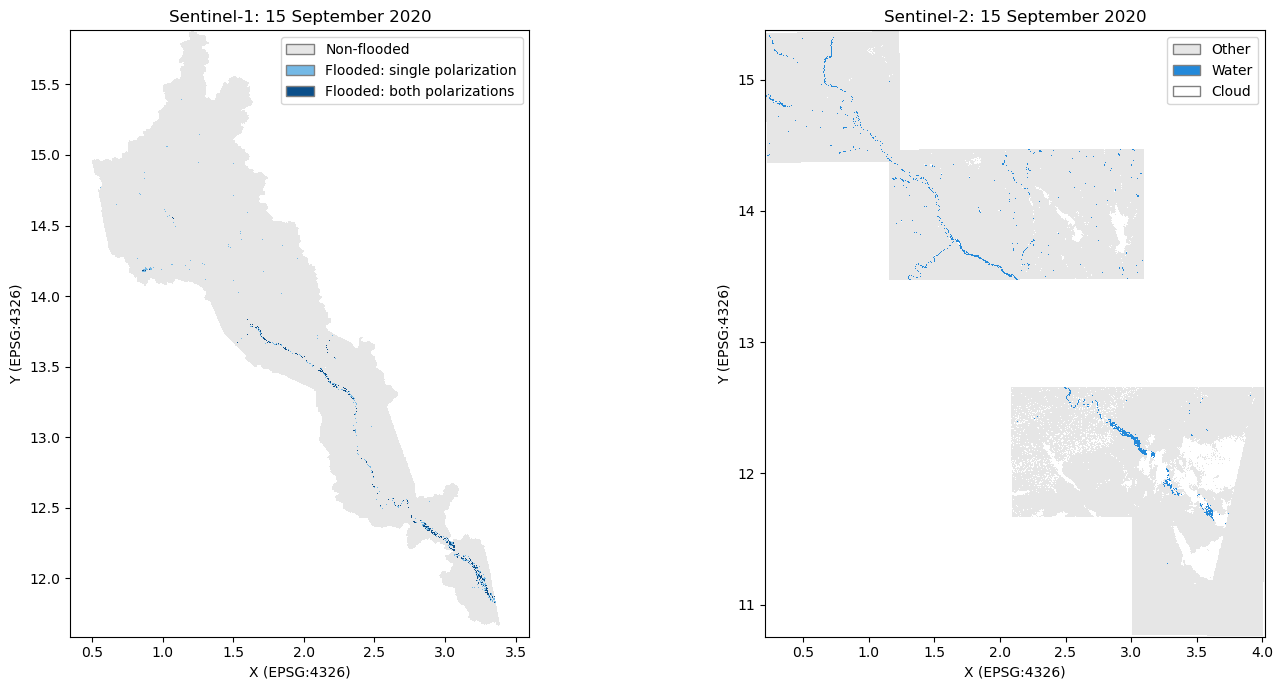

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(15, 7))
plot_classes(s1, s1_extent, s1_crs, ["#e6e6e6", "#74b9e6", "#0b4f8a"], ["Non-flooded", "Flooded: single polarization", "Flooded: both polarizations"], axes[0], "Sentinel-1: 15 September 2020")
plot_classes(s2, s2_extent, s2_crs, ["#e6e6e6", "#2389da", "white"], ["Other", "Water", "Cloud"], axes[1], "Sentinel-2: 15 September 2020")
fig.tight_layout()
plt.show()